In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("seeds/seeds_dataset.txt", sep=r"\s+", header=None)

df.columns = [
    "area", "perimeter", "compactness",
    "kernel_length", "kernel_width",
    "asymmetry_coefficient", "groove_length",
    "class"
]
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns
)

Kích thước dữ liệu (Số mẫu N = 210, Số biến p = 8)

[B3] Số thành phần tối thiểu để giữ >= 90% phương sai là M = 3
Tỷ lệ phương sai tích luỹ tương ứng: 94.55%


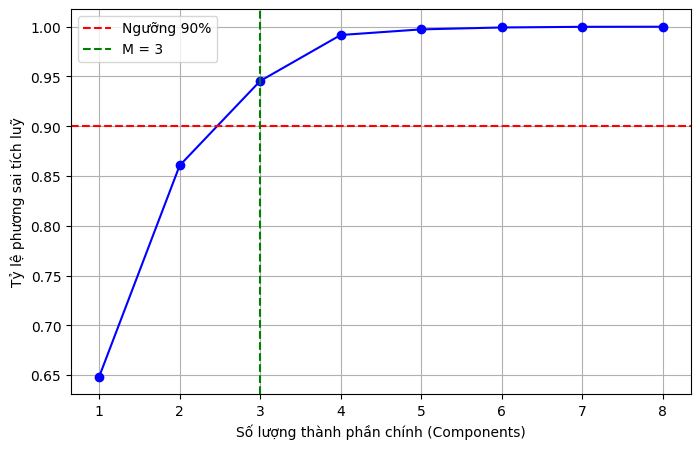

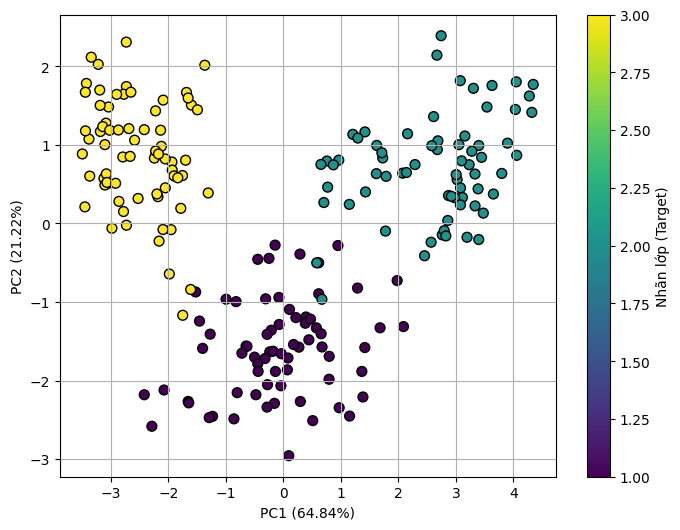

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris


X = df_scaled.to_numpy()
# Chuẩn hoá dữ liệu (Trừ trung bình và chia cho độ lệch chuẩn)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
N, p = X_scaled.shape

print(f"Kích thước dữ liệu (Số mẫu N = {N}, Số biến p = {p})")

# =====================================================================
# B3. Áp dụng PCA, vẽ phương sai giải thích tích luỹ & xác định M (giữ >= 90%)
# =====================================================================
pca = PCA()
pca.fit(X_scaled)

# Tính tỷ lệ phương sai tích luỹ
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Tìm số thành phần tối thiểu M để giữ lại ít nhất 90% (0.90) phương sai
M = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\n[B3] Số thành phần tối thiểu để giữ >= 90% phương sai là M = {M}")
print(f"Tỷ lệ phương sai tích luỹ tương ứng: {cumulative_variance[M-1]*100:.2f}%")

# Vẽ biểu đồ phương sai giải thích tích luỹ
plt.figure(figsize=(8, 5))
plt.plot(range(1, p + 1), cumulative_variance, marker='o', linestyle='-', color='b')
plt.axhline(y=0.90, color='r', linestyle='--', label='Ngưỡng 90%')
plt.axvline(x=M, color='g', linestyle='--', label=f'M = {M}')
plt.xlabel('Số lượng thành phần chính (Components)')
plt.ylabel('Tỷ lệ phương sai tích luỹ')
plt.legend()
plt.grid(True)
plt.show()

# =====================================================================
# B4. Chiếu dữ liệu xuống 2 thành phần chính đầu & vẽ biểu đồ tán xạ
# =====================================================================
pca_2d = PCA(n_components=2)
X_reduced_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_reduced_2d[:, 0], X_reduced_2d[:, 1], c=df["class"], cmap='viridis', edgecolor='k', s=50)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}%)')
plt.grid(True)
plt.colorbar(label='Nhãn lớp (Target)')
plt.show()



In [4]:
import numpy as np
import pandas as pd

# =====================================================================
# LƯU Ý CHUẨN BỊ: Giả sử N (số mẫu), p (số biến), X_scaled (dữ liệu chuẩn hóa tâm),
# và M (số thành phần giữ lại từ B3) đã được xác định từ các bước trước.
# Ví dụ: N, p = X_scaled.shape
# =====================================================================

# =====================================================================
# B5. Thực hiện PCA qua SVD và xác minh hệ thức lambda_d = sigma_d^2 / N
# =====================================================================
# Thực hiện phân rã SVD cho ma trận dữ liệu đã chuẩn hóa tâm: X_scaled = U * S_svd * V^T
U, S_svd, Vt = np.linalg.svd(X_scaled, full_matrices=False)

# Tính giá trị riêng từ SVD theo hệ thức: lambda_d = sigma_d^2 / N
# Lưu ý: Trong một số thư viện, S_svd có thể chứa (N-1) hoặc N tùy quy ước mẫu (ở đây chia cho N theo đúng yêu cầu đề bài)
lambda_from_svd = (S_svd ** 2) / N

# Lấy giá trị riêng từ sklearn PCA (hoặc từ ma trận hiệp phương sai S = (X^T * X) / N)
pca_eigenvalues = pca.explained_variance_ * (
    (N - 1) / N
)  # Quy đổi hệ số hiệu chỉnh mẫu của sklearn nếu cần

print('================ B5: XÁC MINH HỆ THỨC VÀ ĐỘ ỔN ĐỊNH SỐ HỌC ================')
print(f'Số lượng mẫu (N) = {N}, Số biến (p) = {p}\n')

df_b5 = pd.DataFrame({
    'Thành phần (d)': range(1, p + 1),
    'Giá trị riêng từ SVD (sigma_d^2 / N)': lambda_from_svd,
    'Giá trị riêng từ PCA': pca_eigenvalues,
    'Độ lệch tuyệt đối': np.abs(lambda_from_svd - pca_eigenvalues),
})
print(df_b5.to_string(index=False))

print('\n--- Lý do SVD ổn định hơn về mặt số học ---')
print(
    '1. Khi tính PCA bằng cách chéo hóa ma trận hiệp phương sai S ='
    ' (X^T * X) / N, ta phải tính tích vô hướng X^T * X, điều này làm bình'
    ' phương số điều kiện (condition number) của ma trận: kappa(X^T * X) ='
    ' kappa(X)^2. Điều này dễ dẫn đến mất mát độ chính xác số học (sai số làm'
    ' tròn).'
)
print(
    '2. Ngược lại, SVD áp dụng trực tiếp lên ma trận dữ liệu X, tránh được'
    ' việc bình phương số điều kiện, từ đó giữ độ ổn định số học cao hơn rất'
    ' nhiều.'
)

# =====================================================================
# B6. Tái tạo dữ liệu từ M thành phần & đối chiếu sai số với tổng giá trị riêng loại bỏ
# =====================================================================
# Đảm bảo M là số thành phần được xác định từ B3 (Ví dụ: M = 3 hoặc lấy từ biến đã lưu ở B3)
# M = ... (gán giá trị M tìm được ở B3 vào đây nếu chưa có sẵn)

# Lấy M vector trọng số đầu tiên từ V (Vt) -> Kích thước (M x p)
Vt_M = Vt[:M, :]

# Tái tạo lại dữ liệu:
# X_reduced_M: Chiếu dữ liệu xuống M không gian thành phần (N x M)
X_reduced_M = np.dot(X_scaled, Vt_M.T)
# X_reconstructed: Tái tạo lại không gian ban đầu (N x p)
X_reconstructed = np.dot(X_reduced_M, Vt_M)

# Tính sai số tái tạo trung bình (Mean Squared Reconstruction Error) theo tổng bình phương khoảng cách chia cho N
mean_squared_error = np.sum((X_scaled - X_reconstructed) ** 2) / N

# Tổng các giá trị riêng bị loại bỏ (từ thành phần M+1 đến hết)
sum_eigenvalues_dropped = np.sum(pca_eigenvalues[M:])

print(
    '\n================ B6: TÁI TẠO DỮ LIỆU VÀ ĐỐI CHIẾU SAI SỐ ================'
)
print(f'Số thành phần giữ lại (M từ B3) = {M}')
print(f'Sai số tái tạo trung bình (MSE): {mean_squared_error:.6f}')
print(
    'Tổng các giá trị riêng bị loại bỏ (sum_{j>M} lambda_j):'
    f' {sum_eigenvalues_dropped:.6f}'
)
print(
    'Độ lệch tuyệt đối giữa hai giá trị:'
    f' {abs(mean_squared_error - sum_eigenvalues_dropped):.2e}'
)

================ B5: XÁC MINH HỆ THỨC VÀ ĐỘ ỔN ĐỊNH SỐ HỌC ================
Số lượng mẫu (N) = 210, Số biến (p) = 8

 Thành phần (d)  Giá trị riêng từ SVD (sigma_d^2 / N)  Giá trị riêng từ PCA  Độ lệch tuyệt đối
              1                              5.187136              5.187136       8.881784e-16
              2                              1.697881              1.697881       6.661338e-16
              3                              0.679052              0.679052       3.330669e-16
              4                              0.369441              0.369441       3.885781e-16
              5                              0.045135              0.045135       9.714451e-17
              6                              0.015335              0.015335       6.765422e-17
              7                              0.005331              0.005331       2.515349e-16
              8                              0.000690              0.000690       2.611843e-16

--- Lý do SVD ổn định hơn v